<a href="https://colab.research.google.com/github/heyitsjesvin/case_study/blob/main/Case_Study_Starter_Notebook_Airbnb_NYC_Preprocessing_Jesvin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Assessment — NYC Airbnb Data Preprocessing
### Student Name:Jesvin John
### Date:

This notebook is your submission template. Fill in each section — do not delete the headers. Use markdown cells for your written justifications, right next to the code that supports them.

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


---
## Part 1 — Data Understanding & Quality Audit

In [ ]:
# TODO: shape, dtypes, missing value summary
# Check the shape of the dataset
print("Dataset shape:", df.shape)

# Check data types
print("\nData types:")
print(df.dtypes)

# Check memory usage
print("\nMemory usage:")
df.info(memory_usage="deep")

# Check missing values
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

print("\nMissing value summary:")
display(missing[missing["Missing Count"] > 0])

Dataset shape: (48895, 16)

Data types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

Memory usage:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                     

,Missing Count,Missing Percentage
name,16,0.03
host_name,21,0.04
last_review,10052,20.56
reviews_per_month,10052,20.56


In [ ]:
# TODO: check for values that are technically present but don't make real-world sense
# Check invalid or suspicious numeric values
print("Zero prices:", (df["price"] == 0).sum())
print("Negative prices:", (df["price"] < 0).sum())

print("Minimum nights <= 0:", (df["minimum_nights"] <= 0).sum())
print("Minimum nights over 1095:", (df["minimum_nights"] > 1095).sum())

print("Negative reviews:", (df["number_of_reviews"] < 0).sum())

print("Negative availability:", (df["availability_365"] < 0).sum())
print("Availability over 365:", (df["availability_365"] > 365).sum())

# Display suspicious records
suspicious = df[
    (df["price"] <= 0) |
    (df["minimum_nights"] <= 0) |
    (df["minimum_nights"] > 1095) |
    (df["number_of_reviews"] < 0) |
    (df["availability_365"] < 0) |
    (df["availability_365"] > 365)
]

print("\nNumber of suspicious records:", len(suspicious))

display(suspicious[
    ["name", "price", "minimum_nights",
     "number_of_reviews", "availability_365"]
].head(20))

Zero prices: 11
Negative prices: 0
Minimum nights <= 0: 0
Minimum nights over 1095: 1
Negative reviews: 0
Negative availability: 0
Availability over 365: 0

Number of suspicious records: 12


,name,price,minimum_nights,number_of_reviews,availability_365
5767,Prime W. Village location 1 bdrm,180,1250,2,365
23161,"Huge Brooklyn Brownstone Living, Close to it all.",0,4,1,28
25433,★Hostel Style Room | Ideal Traveling Buddies★,0,2,55,127
25634,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",0,2,16,0
25753,"Sunny, Quiet Room in Greenpoint",0,2,12,0
25778,Modern apartment in the heart of Williamsburg,0,5,3,73
25794,Spacious comfortable master bedroom with nice ...,0,1,93,176
25795,Contemporary bedroom in brownstone with nice view,0,1,95,232
25796,Cozy yet spacious private brownstone bedroom,0,1,95,222
26259,the best you can find,0,3,0,0


In [ ]:
# TODO: duplicate check
# Count duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Display duplicate records, if any
display(df[df.duplicated()].head())

Duplicate rows: 0


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365


**Written notes — what did you find, and what looks suspicious?**

### Part 1 — Data Understanding & Quality Audit

The dataset contains Airbnb listings from New York City in 2019. I checked the number of rows and columns, data types, memory usage, missing values, and duplicate records.

I also checked for invalid numeric values that cannot be detected using `isnull()`. A price of zero or a negative price is invalid for normal nightly price prediction. A minimum stay longer than 1,095 nights is unusual and requires investigation. Negative review counts and availability outside the range of 0–365 days would also be invalid.

However, unusually high prices and long minimum stays are not automatically errors because they may represent genuine listing conditions. I would investigate suspicious records before deciding whether to remove or correct them. The actual counts and missing-value percentages are reported by the executed code.

---
## Part 2 — Missing Value Diagnosis & Treatment

In [ ]:
# TODO: investigate missingness pattern(s) across columns
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check whether missing reviews are related to zero reviews
print("\nReview count vs missing last_review:")
display(pd.crosstab(
    df["number_of_reviews"] == 0,
    df["last_review"].isnull()
))

print("\nReview count vs missing reviews_per_month:")
display(pd.crosstab(
    df["number_of_reviews"] == 0,
    df["reviews_per_month"].isnull()
))

# Check missing values by neighbourhood group
for col in ["name", "host_name", "last_review", "reviews_per_month"]:
    print(f"\nMissing {col} by neighbourhood group:")
    display(df.groupby("neighbourhood_group")[col]
              .apply(lambda x: x.isnull().mean().round(3)))

Missing values:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Review count vs missing last_review:


last_review,False,True
number_of_reviews,,
False,38843,0
True,0,10052



Review count vs missing reviews_per_month:


reviews_per_month,False,True
number_of_reviews,,
False,38843,0
True,0,10052



Missing name by neighbourhood group:


,name
neighbourhood_group,
Bronx,0.001
Brooklyn,0.000
Manhattan,0.000
Queens,0.000
Staten Island,0.000


... (2 outputs left out)


Missing last_review by neighbourhood group:


,last_review
neighbourhood_group,
Bronx,0.197
Brooklyn,0.182
Manhattan,0.232
Queens,0.193
Staten Island,0.158



Missing reviews_per_month by neighbourhood group:


,reviews_per_month
neighbourhood_group,
Bronx,0.197
Brooklyn,0.182
Manhattan,0.232
Queens,0.193
Staten Island,0.158


**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

### Part 2 — Missing Value Diagnosis

The main columns with missing values in the NYC Airbnb dataset are `name`, `host_name`, `last_review`, and `reviews_per_month`. I used missing-value counts and cross-tabulations to investigate their patterns.

- **`name`:** The missingness may be MAR if it is associated with listing characteristics, but this needs further evidence. The missingness mechanism cannot be confirmed from the missing-value count alone.
- **`host_name`:** The missingness may be MAR if it is associated with other listing or host characteristics. Further investigation is needed.
- **`last_review`:** Its missingness is strongly associated with listings that have no reviews. A listing with zero reviews has no review date to record, so this is structural missingness rather than necessarily a data-entry error.
- **`reviews_per_month`:** Its missingness is also strongly associated with listings that have no reviews. For such listings, a value of zero is a reasonable representation of the review rate.

MCAR means missing completely at random, MAR means missingness is associated with observed information, and MNAR means missingness depends on the missing value itself or unobserved information. These classifications are hypotheses based on the observed data, not definitive proof.

In [ ]:
# TODO: apply your chosen treatment(s)
# Make a copy of the original dataset
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Remove invalid prices
df_clean = df_clean[df_clean["price"] > 0].copy()

# Fill missing text fields
df_clean["name"] = df_clean["name"].fillna("Unknown")
df_clean["host_name"] = df_clean["host_name"].fillna("Unknown")

# Listings with no reviews have a review rate of zero
no_reviews = df_clean["number_of_reviews"] == 0

df_clean.loc[
    no_reviews & df_clean["reviews_per_month"].isnull(),
    "reviews_per_month"
] = 0

# Check missing values after treatment
print("Missing values after treatment:")
print(df_clean.isnull().sum())

Missing values after treatment:
id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10051
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64


**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**
### Missing Value Treatment

I removed exact duplicate rows and records with zero or negative prices because they are unsuitable for the intended nightly price prediction task. Missing `name` and `host_name` values were replaced with `"Unknown"` so the records could be retained. For listings with zero reviews, missing `reviews_per_month` values were replaced with zero because they have not received reviews.

I would not automatically fill every missing `last_review` value with a date. Instead, I would exclude this field from the prediction model because review dates may not be available when a new listing is launched.

Using `df.dropna()` on the entire dataset could remove many otherwise useful listings and introduce bias. Treating each missing column according to its meaning preserves more valid data and makes the cleaning decisions easier to justify.

---
## Part 3 — Outlier Detection & Treatment


Column: price
Lower limit: -90.0
Upper limit: 334.0
Number of outliers: 2972

Column: minimum_nights
Lower limit: -5.0
Upper limit: 11.0
Number of outliers: 6605


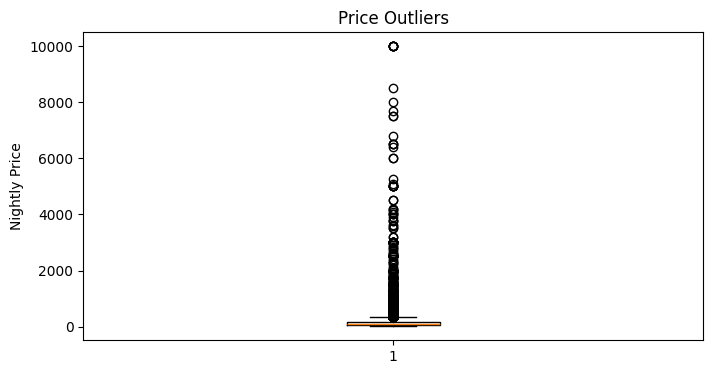

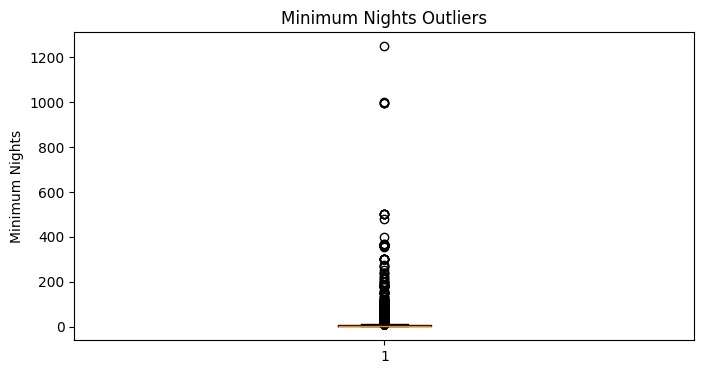

,name,neighbourhood_group,room_type,price,minimum_nights
9151,Furnished room in Astoria apartment,Queens,Private room,10000,100
17692,Luxury 1 bedroom apt. -stunning Manhattan views,Brooklyn,Entire home/apt,10000,5
29238,1-BR Lincoln Center,Manhattan,Entire home/apt,10000,30
12342,"Quiet, Clean, Lit @ LES & Chinatown",Manhattan,Private room,9999,99
40433,2br - The Heart of NYC: Manhattans Lower East ...,Manhattan,Entire home/apt,9999,30
6530,Spanish Harlem Apt,Manhattan,Entire home/apt,9999,5
30268,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,Manhattan,Entire home/apt,8500,30
4377,Film Location,Brooklyn,Entire home/apt,8000,1
29662,East 72nd Townhouse by (Hidden by Airbnb),Manhattan,Entire home/apt,7703,1
45666,Gem of east Flatbush,Brooklyn,Private room,7500,1


In [ ]:
# TODO: detect outliers in at least two numeric columns
import matplotlib.pyplot as plt

# Use the IQR method to detect outliers
def detect_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

    print(f"\nColumn: {column}")
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))

    return outliers

price_outliers = detect_outliers(df_clean, "price")
minimum_night_outliers = detect_outliers(
    df_clean, "minimum_nights"
)

# Plot the distributions
plt.figure(figsize=(8, 4))
plt.boxplot(df_clean["price"])
plt.title("Price Outliers")
plt.ylabel("Nightly Price")
plt.show()

plt.figure(figsize=(8, 4))
plt.boxplot(df_clean["minimum_nights"])
plt.title("Minimum Nights Outliers")
plt.ylabel("Minimum Nights")
plt.show()

# Inspect the highest-priced listings
display(
    df_clean.sort_values("price", ascending=False)[
        ["name", "neighbourhood_group", "room_type",
         "price", "minimum_nights"]
    ].head(10)
)

**Written justification — for each outlier group, is it an error or a genuine listing? What evidence supports your call?**
### Outlier Detection and Interpretation

I used the Interquartile Range (IQR) method to detect outliers in `price` and `minimum_nights`. The IQR method is useful because these numeric variables can be highly skewed, and the method is less affected by extreme values than a mean-and-standard-deviation rule.

A very high nightly price may be genuine, for example, for a luxury property in Manhattan. A low price may also be genuine if it represents a budget or shared room. Therefore, high prices should not automatically be deleted simply because they fall outside the IQR limits.

A minimum stay longer than three years is unusual, but it could reflect a listing's restrictions. I would inspect the listing details before classifying it as an error. A zero or negative price, on the other hand, is invalid for this prediction task and is removed during cleaning.

Treating every statistical outlier in the same way could remove genuine properties and reduce the model's ability to predict prices across different types of accommodation.

In [ ]:
# TODO: apply treatment consistent with your judgment above
# Start from the cleaned dataset
df_model_data = df_clean.copy()

# Keep genuine high prices, but limit extreme minimum-stay values
# to a practical upper bound of 1095 nights.
df_model_data["minimum_nights"] = (
    df_model_data["minimum_nights"].clip(upper=1095)
)

print("Rows after cleaning:", len(df_model_data))
print("Minimum nights above 1095 after treatment:",
      (df_model_data["minimum_nights"] > 1095).sum())
print("Maximum price retained:", df_model_data["price"].max())

Rows after cleaning: 48884
Minimum nights above 1095 after treatment: 0
Maximum price retained: 10000


---
## Part 4 — Feature Engineering & Encoding

In [ ]:
# TODO: encode categorical columns appropriately
# Identify categorical columns
categorical_columns = df_model_data.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nUnique values in selected categorical columns:")
for col in ["neighbourhood_group", "neighbourhood", "room_type"]:
    print(f"\n{col}:")
    print(df_model_data[col].nunique(), "unique values")

Categorical columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']

Unique values in selected categorical columns:

neighbourhood_group:
5 unique values

neighbourhood:
221 unique values

room_type:
3 unique values


In [ ]:
# TODO: engineer at least two new features
# Feature 1: Proportion of the year the listing is available
df_model_data["availability_rate"] = (
    df_model_data["availability_365"] / 365
)

# Feature 2: Identify shared-room listings
df_model_data["is_shared_room"] = (
    df_model_data["room_type"] == "Shared room"
).astype(int)

# Display the new features
display(df_model_data[
    ["availability_365", "availability_rate",
     "room_type", "is_shared_room"]
].head())

,availability_365,availability_rate,room_type,is_shared_room
0,365,1.000000,Private room,0
1,355,0.972603,Entire home/apt,0
2,365,1.000000,Private room,0
3,194,0.531507,Entire home/apt,0
4,0,0.000000,Entire home/apt,0


**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

### Feature Engineering and Encoding

The categorical columns `neighbourhood_group`, `neighbourhood`, and `room_type` are nominal because their categories do not have a natural order. They should be encoded using one-hot encoding. The dataset does not contain an obvious ordinal categorical variable that requires ordinal encoding.

I created two new features:

1. **`availability_rate`:** This is `availability_365 / 365`. It represents the proportion of the year a listing is available and may help explain differences in pricing.
2. **`is_shared_room`:** This is 1 when the room type is a shared room and 0 otherwise. Shared rooms may have different prices from entire homes or private rooms.

For a model intended to predict the price of a new listing, I would exclude `id`, `host_id`, `name`, `host_name`, `last_review`, `number_of_reviews`, and `reviews_per_month`. IDs are identifiers rather than useful general pricing features, and names are high-cardinality text fields. Review information may not exist when a listing is first launched and could create information leakage. The exclusion depends on the prediction scenario; review features could be considered for a different task involving already established listings.

---
## Part 5 — Build a Reusable Preprocessing Pipeline

In [ ]:
# TODO: train/test split (before fitting anything)
from sklearn.model_selection import train_test_split

# Columns excluded from price prediction
drop_columns = [
    "price",
    "id",
    "host_id",
    "name",
    "host_name",
    "last_review",
    "number_of_reviews",
    "reviews_per_month"
]

# Create features and target
X = df_model_data.drop(
    columns=drop_columns,
    errors="ignore"
)

y = df_model_data["price"]

# Split before fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (39107, 10)
Testing data shape: (9777, 10)


In [ ]:
# TODO: build Pipeline combining your cleaning, imputation, encoding, scaling steps
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Identify numeric and categorical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numeric preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Complete model pipeline
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the pipeline
model_pipeline.fit(X_train, y_train)

# Predict prices for test data
y_pred = model_pipeline.predict(X_test)

# Evaluate model performance
print("Mean Absolute Error (MAE):",
      mean_absolute_error(y_test, y_pred))

print("R-squared (R²):",
      r2_score(y_test, y_pred))

Mean Absolute Error (MAE): 67.25195561010536
R-squared (R²): 0.05530130991989046


---
## Part 6 — Written Reflection

1. **Largest-impact decision:** Handling invalid/non-positive prices and retaining genuine high-price listings is likely to have a major effect because price is the target itself and extreme target errors can dominate model fitting. I would verify the effect by comparing validation metrics from a baseline with the cleaned dataset and inspecting residuals; the exact impact must be measured, not assumed.

2. **Live listing data:** The pipeline should be deployed as a saved, fitted scikit-learn pipeline and monitored for schema changes, new categories, missingness shifts, and price drift. The pipeline should be refitted on a scheduled basis using newly reviewed training data, rather than fitting imputers or encoders separately for each incoming batch.

3. **Two-sentence stakeholder answer:** Deleting every row with a missing or unusual value would throw away valid listings, especially new listings with no reviews, and could make the training data unrepresentative. We instead distinguish clear data errors from genuine unusual properties, apply column-specific treatments, and keep preprocessing inside a train-fitted pipeline to reduce bias and data leakage.